# 04 — Uplift and campaign simulation

> **Data sources:** Cell2Cell telecom churn (`jpacse/datasets-for-churn-telecom`, Kaggle mirror of the Teradata/Duke data) and the Hillstrom MineThatData e-mail experiment (minethatdata.com). **Downloaded:** 2026-08-10. Run `make data` to reproduce `data/raw/`.

The differentiator: who is worth contacting, not just who will act. A two-model T-learner on the randomized experiment, then a campaign.

In [1]:
from churn_uplift.data import hillstrom_parts, load_hillstrom, stratified_split
from churn_uplift.evaluation import (
    average_treatment_effect,
    best_fraction,
    campaign_simulation,
    plots,
    qini_coefficient,
    qini_curve,
    uplift_by_decile,
)
from churn_uplift.models import UpliftTLearner

df = load_hillstrom()
train, test = stratified_split(df, stratify_cols=["treatment", "outcome"])
X_tr, t_tr, y_tr = hillstrom_parts(train)
X_te, t_te, y_te = hillstrom_parts(test)
print(
    "ATE (visit):", round(average_treatment_effect(df["treatment"], df["outcome"]), 4)
)
model = UpliftTLearner().fit(X_tr, t_tr, y_tr)
uplift = model.predict_uplift(X_te)
print("Qini coefficient:", round(qini_coefficient(uplift, t_te, y_te), 5))

ATE (visit): 0.0766


Qini coefficient: 0.00171


## Qini curve

Incremental responses captured vs. the random baseline.

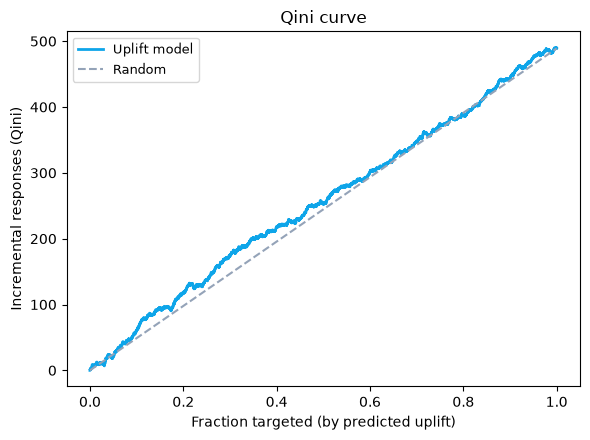

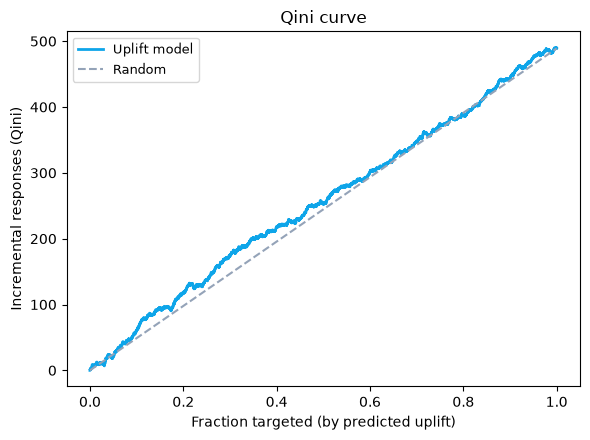

In [2]:
plots.plot_qini(qini_curve(uplift, t_te, y_te))

## Uplift by decile (validation)

The top decile should show the largest treated−control gap; 'sleeping dogs' can go negative.

,decile,n,resp_treated,resp_control,observed_uplift
0,1,1279,0.2373,0.1422,0.0951
1,2,1278,0.2226,0.1312,0.0913
2,3,1278,0.1978,0.1125,0.0853
3,4,1279,0.1863,0.1152,0.0711
4,5,1278,0.1578,0.1050,0.0528
5,6,1278,0.1777,0.0991,0.0786
6,7,1279,0.1513,0.0777,0.0736
7,8,1278,0.1585,0.0932,0.0653
8,9,1278,0.1602,0.0758,0.0844
9,10,1279,0.1797,0.1099,0.0699


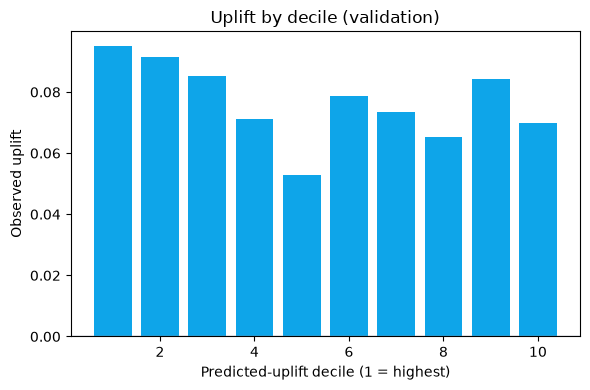

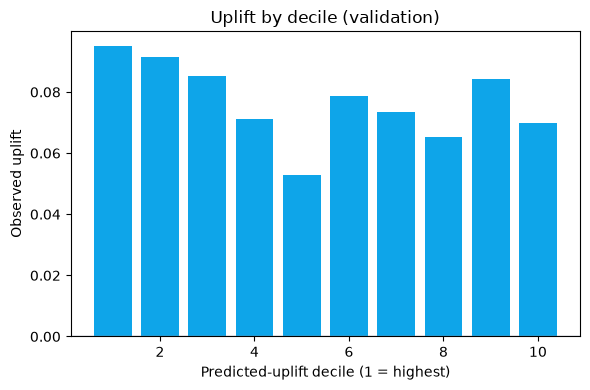

In [3]:
dec = uplift_by_decile(uplift, t_te, y_te)
display(dec)
plots.plot_uplift_by_decile(dec)

## Campaign simulation

Scenario: 0.40 cost per contact, 5.0 value per incremental response. How far should the campaign reach?

best targeting fraction: 0.3


,fraction,n_targeted,incremental_rate,incremental_responses,cost,value,net_value,roi
0,0.1,1278,0.0965,123.3,511.2,616.5,105.3,0.206
1,0.2,2557,0.0932,238.2,1022.8,1191.2,168.4,0.165
2,0.3,3835,0.0903,346.3,1534.0,1731.7,197.7,0.129
3,0.4,5114,0.0857,438.1,2045.6,2190.4,144.8,0.071
4,0.5,6392,0.0787,502.9,2556.8,2514.3,-42.5,-0.017
5,0.7,8949,0.0778,696.5,3579.6,3482.6,-97.0,-0.027
6,1.0,12784,0.0765,978.0,5113.6,4890.0,-223.6,-0.044


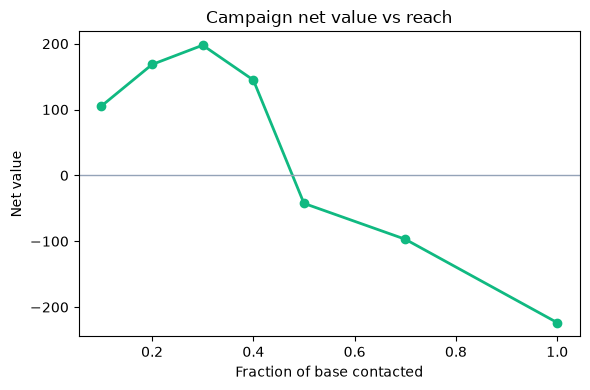

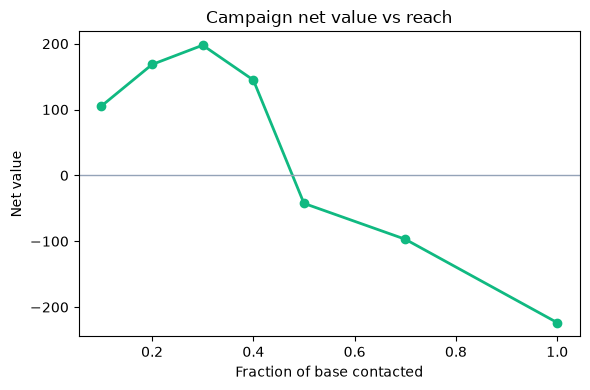

In [4]:
sim = campaign_simulation(
    uplift, t_te, y_te, cost_per_contact=0.40, value_per_response=5.0
)
print("best targeting fraction:", best_fraction(sim))
display(sim)
plots.plot_campaign(sim)

## Conclusion

The men's e-mail lifts visits by ~7.7 pp on average, and the model concentrates uplift in the top decile (~2x the middle). Under the scenario economics, contacting the top ~30% by predicted uplift maximises net value — beyond that, contact costs more than the incremental value it buys. Predicting churn is not the same as deciding a campaign.